# 04_baseline_comparison.ipynb

## 목적
LightGBM, XGBoost, CatBoost, Random Forest 4개 모델을 동일한 조건(기본 파라미터)으로 학습하여 베이스라인 성능을 비교합니다.
여기서 가장 성능이 좋은 상위 2개 모델만 다음 단계(05_tuning)에서 하이퍼파라미터 튜닝을 진행합니다.

## 목차
1. 환경 세팅 및 데이터 로드
2. NaN 처리 (Random Forest 전용 데이터셋 별도 준비)
3. 모델 1 — LightGBM 베이스라인
4. 모델 2 — XGBoost 베이스라인
5. 모델 3 — CatBoost 베이스라인
6. 모델 4 — Random Forest 베이스라인
7. 베이스라인 성능 종합 비교
8. 결과 저장


## 1. 환경 세팅 및 데이터 로드

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time, os

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

plt.rc('font', family='Malgun Gothic')  # Mac: 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:.4f}'.format
print('라이브러리 임포트 완료')


라이브러리 임포트 완료


In [2]:
# 03_preprocessing_v2에서 저장한 분할 데이터를 그대로 불러옵니다.
X_train = pd.read_csv('../data/X_train_v2.csv')
X_val   = pd.read_csv('../data/X_val_v2.csv')
y_train = pd.read_csv('../data/y_train_v2.csv').squeeze()
y_val   = pd.read_csv('../data/y_val_v2.csv').squeeze()

print(f'X_train: {X_train.shape}, X_val: {X_val.shape}')
print(f'y_train 이탈률: {y_train.mean():.4f}')
print(f'y_val   이탈률: {y_val.mean():.4f}')


X_train: (914921, 50), X_val: (228731, 50)
y_train 이탈률: 0.5002
y_val   이탈률: 0.5002


## 2. NaN 처리 (Random Forest 전용 데이터셋 별도 준비)

LightGBM, XGBoost, CatBoost는 NaN을 자체적으로 처리할 수 있어 원본 그대로 사용합니다.
Random Forest는 NaN을 처리하지 못하므로, **Random Forest 전용 복사본**을 따로 만들어 median으로 대치합니다.
(원본 X_train, X_val은 그대로 둬야 다른 모델에서 재사용 가능)


In [3]:
nan_cols = [
    'avg_purchase_interval', 'std_purchase_interval', 'last_interval',
    'freq_decay_rate', 'recent_price_ratio', 'interval_acceleration'
]

X_train_rf = X_train.copy()
X_val_rf   = X_val.copy()

for col in nan_cols:
    if col in X_train_rf.columns:
        median_val = X_train_rf[col].median()
        X_train_rf[col] = X_train_rf[col].fillna(median_val)
        X_val_rf[col]   = X_val_rf[col].fillna(median_val)

print(f'Random Forest 전용 데이터셋 준비 완료, 결측치: {X_train_rf.isnull().sum().sum()}')


Random Forest 전용 데이터셋 준비 완료, 결측치: 0


In [4]:
# 모든 모델의 결과를 여기에 순서대로 저장합니다.
baseline_results = []


## 3. 모델 1 — LightGBM 베이스라인

In [5]:
model_lgbm = lgb.LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1)

start = time.time()
model_lgbm.fit(X_train, y_train)
elapsed = time.time() - start

pred  = model_lgbm.predict(X_val)
proba = model_lgbm.predict_proba(X_val)[:, 1]

baseline_results.append({
    'model'     : 'LightGBM',
    'accuracy'  : round(accuracy_score(y_val, pred), 4),
    'auc_roc'   : round(roc_auc_score(y_val, proba), 4),
    'f1_score'  : round(f1_score(y_val, pred), 4),
    'train_time': round(elapsed, 1)
})

print(f'LightGBM 완료 — AUC: {baseline_results[-1]["auc_roc"]}, 시간: {elapsed:.1f}초')


LightGBM 완료 — AUC: 0.8477, 시간: 5.9초


## 4. 모델 2 — XGBoost 베이스라인

In [6]:
model_xgb = xgb.XGBClassifier(
    random_state=42, n_jobs=-1, verbosity=0,
    eval_metric='auc', use_label_encoder=False
)

start = time.time()
model_xgb.fit(X_train, y_train)
elapsed = time.time() - start

pred  = model_xgb.predict(X_val)
proba = model_xgb.predict_proba(X_val)[:, 1]

baseline_results.append({
    'model'     : 'XGBoost',
    'accuracy'  : round(accuracy_score(y_val, pred), 4),
    'auc_roc'   : round(roc_auc_score(y_val, proba), 4),
    'f1_score'  : round(f1_score(y_val, pred), 4),
    'train_time': round(elapsed, 1)
})

print(f'XGBoost 완료 — AUC: {baseline_results[-1]["auc_roc"]}, 시간: {elapsed:.1f}초')


XGBoost 완료 — AUC: 0.8481, 시간: 10.1초


## 5. 모델 3 — CatBoost 베이스라인

In [7]:
model_cb = CatBoostClassifier(random_state=42, verbose=0)

start = time.time()
model_cb.fit(X_train, y_train)
elapsed = time.time() - start

pred  = model_cb.predict(X_val)
proba = model_cb.predict_proba(X_val)[:, 1]

baseline_results.append({
    'model'     : 'CatBoost',
    'accuracy'  : round(accuracy_score(y_val, pred), 4),
    'auc_roc'   : round(roc_auc_score(y_val, proba), 4),
    'f1_score'  : round(f1_score(y_val, pred), 4),
    'train_time': round(elapsed, 1)
})

print(f'CatBoost 완료 — AUC: {baseline_results[-1]["auc_roc"]}, 시간: {elapsed:.1f}초')


CatBoost 완료 — AUC: 0.8485, 시간: 162.3초


## 6. 모델 4 — Random Forest 베이스라인

In [8]:
# NaN 처리된 전용 데이터셋(X_train_rf) 사용
model_rf = RandomForestClassifier(random_state=42, n_jobs=-1)

start = time.time()
model_rf.fit(X_train_rf, y_train)
elapsed = time.time() - start

pred  = model_rf.predict(X_val_rf)
proba = model_rf.predict_proba(X_val_rf)[:, 1]

baseline_results.append({
    'model'     : 'RandomForest',
    'accuracy'  : round(accuracy_score(y_val, pred), 4),
    'auc_roc'   : round(roc_auc_score(y_val, proba), 4),
    'f1_score'  : round(f1_score(y_val, pred), 4),
    'train_time': round(elapsed, 1)
})

print(f'Random Forest 완료 — AUC: {baseline_results[-1]["auc_roc"]}, 시간: {elapsed:.1f}초')


Random Forest 완료 — AUC: 0.8357, 시간: 130.6초


## 7. 베이스라인 성능 종합 비교

In [9]:
result_df = pd.DataFrame(baseline_results).sort_values('auc_roc', ascending=False).reset_index(drop=True)
print('--- 베이스라인 성능 비교 (AUC 기준 정렬) ---')
print(result_df.to_string(index=False))


--- 베이스라인 성능 비교 (AUC 기준 정렬) ---
       model  accuracy  auc_roc  f1_score  train_time
    CatBoost    0.7687   0.8485    0.7723    162.3000
     XGBoost    0.7689   0.8481    0.7722     10.1000
    LightGBM    0.7686   0.8477    0.7714      5.9000
RandomForest    0.7587   0.8357    0.7583    130.6000


C:\Users\09048\AppData\Local\Temp\ipykernel_28384\1493721741.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=result_df, x='model', y='auc_roc', ax=axes[0], palette='viridis')
C:\Users\09048\AppData\Local\Temp\ipykernel_28384\1493721741.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=result_df, x='model', y='train_time', ax=axes[1], palette='magma')
C:\Users\09048\AppData\Local\Temp\ipykernel_28384\1493721741.py:15: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_28384\1493721741.py:15: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) Arial.
  plt.tight_la

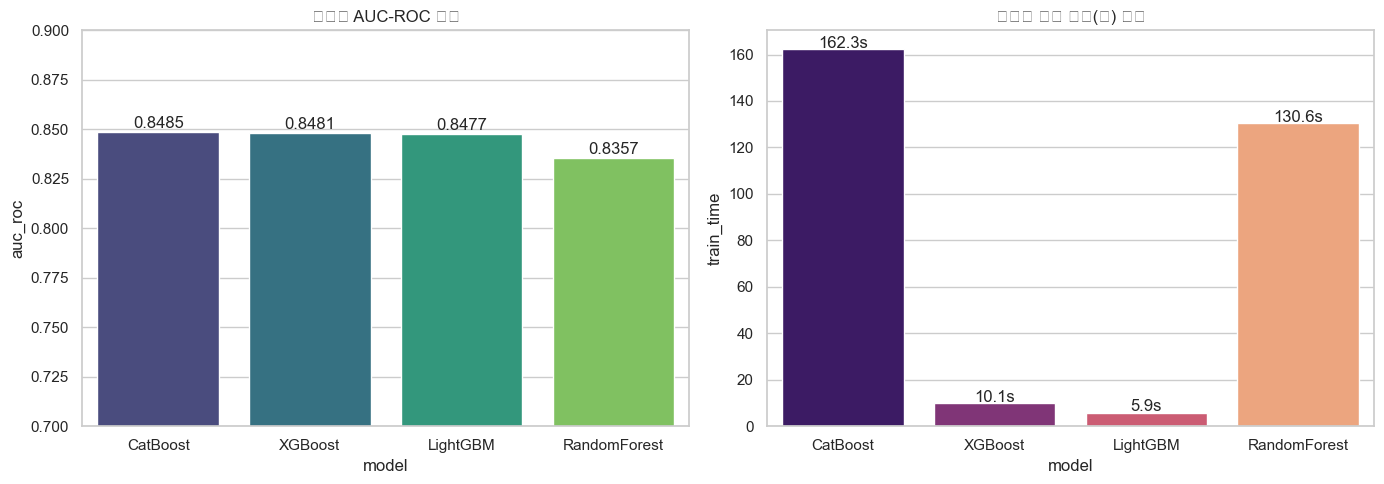

In [10]:
# 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=result_df, x='model', y='auc_roc', ax=axes[0], palette='viridis')
axes[0].set_title('모델별 AUC-ROC 비교')
axes[0].set_ylim(0.7, 0.9)
for i, v in enumerate(result_df['auc_roc']):
    axes[0].text(i, v + 0.002, f'{v:.4f}', ha='center')

sns.barplot(data=result_df, x='model', y='train_time', ax=axes[1], palette='magma')
axes[1].set_title('모델별 학습 시간(초) 비교')
for i, v in enumerate(result_df['train_time']):
    axes[1].text(i, v + 0.5, f'{v:.1f}s', ha='center')

plt.tight_layout()
plt.show()


In [11]:
# 상위 2개 모델 확인 → 05_tuning 단계로 전달
top2 = result_df.head(2)['model'].tolist()
print(f'AUC 기준 상위 2개 모델: {top2}')
print('이 2개 모델을 05_tuning_model1.ipynb, 05_tuning_model2.ipynb에서 각각 튜닝합니다.')


AUC 기준 상위 2개 모델: ['CatBoost', 'XGBoost']
이 2개 모델을 05_tuning_model1.ipynb, 05_tuning_model2.ipynb에서 각각 튜닝합니다.


## 8. 결과 저장

In [12]:
os.makedirs('../results', exist_ok=True)
result_df.to_csv('../results/baseline_comparison_v2.csv', index=False)
print('베이스라인 비교 결과 저장 완료: ../results/baseline_comparison_v2.csv')


베이스라인 비교 결과 저장 완료: ../results/baseline_comparison_v2.csv
